<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Integral%20estoc%C3%A1stica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:olive;"> **INTEGRAL ESTOCÁSTICA** </span>

<span style="color:teal;">**Nombre:** </span> Jerónimo López Annette Michelle

<span style="color:olive;">**Objetivo.**  comprobar numéricamente, mediante simulación Monte Carlo, los resultados teóricos del Ejercicio 1 para la integral del cuadrado del movimiento browniano:</span>

$$I=\int_0^1 W_s^2\,ds .$$

Resultados teóricos (para $t=1$):

$$\mathbb{E}\left[\int_0^1 W_s^2\,ds\right]=\frac{t^2}{2}=\frac{1^2}{2}=0.5,\qquad
\mathrm{Var}\left[\int_0^1 W_s^2\,ds\right]=\frac{t^2}{3}=\frac{1^4}{3}=\approx 0.3333 .$$


Se estudiará la EDE:

$$
dY_t=rY_t\,dt+\sigma Y_t\,dB_t,\qquad Y_0=1,
$$

donde $B_t$ es un movimiento browniano estándar.


### <span style="color:olive;">**Actividad 2: Ejercicio 2: Comprobación por simulación para $t=1$**</span>


 <span style="color:teal;">**Fundamento teórico**</span>

**Media.** Por Fubini y $\mathbb{E}[W_s^2]=s$:
$$\mathbb{E}[I]=\int_0^1 \mathbb{E}[W_s^2]\,ds=\int_0^1 s\,ds=\frac12 .$$

**Segundo momento.** Con el teorema de Isserlis (Wick) para variables gaussianas centradas,
$\mathbb{E}[W_s^2W_u^2]=su+2\min(s,u)^2$, por lo que
$$\mathbb{E}[I^2]=\int_0^1\!\!\int_0^1 \big(su+2\min(s,u)^2\big)\,ds\,du=\frac14+2\cdot\frac16=\frac7{12}.$$

**Varianza.**
$$\mathrm{Var}[I]=\mathbb{E}[I^2]-\mathbb{E}[I]^2=\frac7{12}-\frac14=\frac13 .$$


Importamos las Librerías y usamos los parámetros del problema

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd

Se fija una semilla para manejar números aleatorios

In [77]:
# Semilla para reproducibilidad
rng = np.random.default_rng(seed=2026)

In [78]:
# ---- Parámetros de la simulación ----
T = 1.0        # horizonte de tiempo t = 1
N = 1000       # número de pasos de discretización
M = 10_000     # número de trayectorias (réplicas Monte Carlo)
dt = T / N     # paso de tiempo

Del <span style="color:olive;">**Ejercicio 1**</span> tenemos que:

$$\mathbb{E}\left[\int_0^1 W_s^2\,ds\right]=\frac{t^2}{2},\qquad
\mathrm{Var}\left[\int_0^1 W_s^2\,ds\right]=\frac{t^2}{3}$$

In [79]:
# ---- Valores teóricos (Ejercicio 1) ----
media_teorica = T**2 / 2
var_teorica   = T**4 / 3

In [80]:
print(f"dt = {dt}")
print(f"E[I]   teórica = {media_teorica}")
print(f"Var[I] teórica = {var_teorica:.6f}")

dt = 0.001
E[I]   teórica = 0.5
Var[I] teórica = 0.333333


 <span style="color:teal;"> **Algoritmo de simulación**</span>

1. **Discretización:** dividir $[0,1]$ en $N$ pasos, $\Delta t=1/N$, $t_i=i\Delta t$.
2. **Camino browniano:** $Z_i\sim N(0,1)$ i.i.d., $W_{t_i}=W_{t_{i-1}}+\sqrt{\Delta t}\,Z_i$, con $W_0=0$.
3. **Integral (suma de Riemann):** $I=\sum_{i=1}^N W_{t_i}^2\,\Delta t$.
4. **Repetir** los pasos 2–3 $M$ veces para obtener $I_1,\dots,I_M$.
5. **Estimar:** $\bar I=\frac1M\sum_j I_j$ y $S^2=\frac1{M-1}\sum_j (I_j-\bar I)^2$.

In [81]:
t = np.linspace(0, T, N + 1)             # t_0, ..., t_N
Z = rng.standard_normal(N)               # Z_i ~ N(0,1)
W = np.concatenate(([0.0], np.cumsum(np.sqrt(dt) * Z)))   # W_0 = 0, W_i = W_{i-1} + sqrt(dt) Z_i

In [82]:
I_una = np.sum(W[1:]**2) * dt            # I = sum_{i=1}^N W_{t_i}^2 dt

Graficamos para ver el comportamiento de estas trayectorias

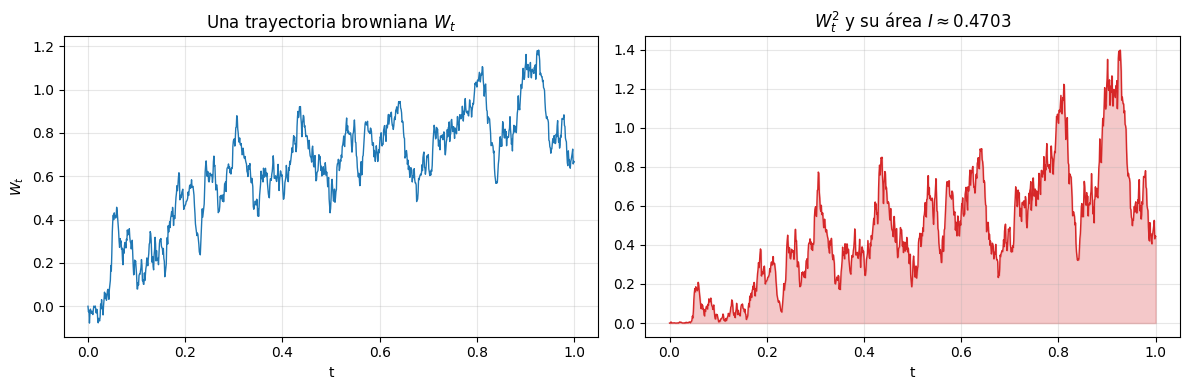

In [83]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t, W, lw=1)
ax[0].set_title("Una trayectoria browniana $W_t$")
ax[0].set_xlabel("t"); ax[0].set_ylabel("$W_t$"); ax[0].grid(alpha=.3)

ax[1].plot(t, W**2, lw=1, color="tab:red")
ax[1].fill_between(t, W**2, alpha=.25, color="tab:red")
ax[1].set_title(f"$W_t^2$ y su área $I\\approx{I_una:.4f}$")
ax[1].set_xlabel("t"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### <span style="color:olive;">**Simulación Monte Carlo vectorizada**</span>

Generar una matriz de $M\times N$ normales ocupa $\approx 80$ MB para $M=10^4$, $N=10^3$.
Para que el código sea escalable se procesa **por lotes** (*batches*), de modo que se pueda subir $M$ sin agotar memoria.

In [84]:
def simular_integral(M, N, T=1.0, batch=2000, rng=rng):
    '''
    Simula M valores de I = sum_{i=1}^N W_{t_i}^2 * dt.

    Parámetros
    ----------
    M     : número de trayectorias
    N     : pasos de discretización
    T     : horizonte de tiempo
    batch : trayectorias por lote (controla el uso de memoria)

    Devuelve
    --------
    I : arreglo de longitud M con las realizaciones de la integral
    '''
    dt = T / N
    I = np.empty(M)
    hecho = 0
    while hecho < M:
        m = min(batch, M - hecho)
        Z = rng.standard_normal((m, N))                 # m trayectorias x N incrementos
        W = np.cumsum(np.sqrt(dt) * Z, axis=1)          # W_{t_1}, ..., W_{t_N} (W_0 = 0 implícito)
        I[hecho:hecho + m] = np.sum(W**2, axis=1) * dt  # suma de Riemann
        hecho += m
    return I


In [85]:
I = simular_integral(M, N, T)
print("Primeros 5 valores de I:", np.round(I[:5], 4))

Primeros 5 valores de I: [2.4432 0.3648 0.2029 0.2169 0.9001]


### <span style="color:olive;">**Estimadores: media y varianza muestral**</span>

$$\bar I=\frac1M\sum_{j=1}^M I_j,\qquad S^2=\frac1{M-1}\sum_{j=1}^M (I_j-\bar I)^2 .$$

In [86]:
I_barra = I.mean()
S2      = I.var(ddof=1)          # ddof=1  ->  divide entre (M-1)


In [87]:
# Errores estándar de los estimadores
ee_media = np.sqrt(S2 / M)
# Var(S^2) ≈ (mu4 - sigma^4 (M-3)/(M-1)) / M ; usamos el momento central 4 muestral
mu4 = np.mean((I - I_barra)**4)
ee_var = np.sqrt((mu4 - S2**2) / M)

Para tener una mejor visualización podemos usar una tabla para comparar el valor real vs el simulado

In [88]:
filas = [
    ("Media E[I]",      media_teorica, I_barra, ee_media),
    ("Varianza Var[I]", var_teorica,   S2,      ee_var),
]

encabezado = f"{'Cantidad':<17}{'Teórico':>10}{'Simulado':>11}{'EE (MC)':>10}{'Error abs.':>12}{'Error rel.(%)':>15}{'|Error|/EE':>12}"
print(encabezado)
print("-" * len(encabezado))
for nombre, teo, sim, ee in filas:
    err = abs(sim - teo)
    print(f"{nombre:<17}{float(teo):>10.5f}{float(sim):>11.5f}{float(ee):>10.5f}"
          f"{float(err):>12.5f}{100*float(err)/float(teo):>15.3f}{float(err)/float(ee):>12.3f}")

Cantidad            Teórico   Simulado   EE (MC)  Error abs.  Error rel.(%)  |Error|/EE
---------------------------------------------------------------------------------------
Media E[I]          0.50000    0.49646   0.00564     0.00354          0.709       0.628
Varianza Var[I]     0.33333    0.31847   0.01066     0.01486          4.459       1.395


### <span style="color:olive;">**Con el uso de Intervalos de confianza al 95 % para validar la simulación**</span>


* Para la **media**: $\bar I \pm t_{M-1,0.975}\,S/\sqrt M$.
* Para la **varianza**: $S^2 \pm 1.96\,\widehat{EE}(S^2)$, con $\widehat{EE}(S^2)=\sqrt{(\hat\mu_4-S^4)/M}$ (método asintótico basado en el cuarto momento central).
  **No** se usa el intervalo $\chi^2$ clásico, porque exige que los datos sean normales y aquí $I$ es fuertemente asimétrica y de colas pesadas (ver sección 7); ese intervalo quedaría demasiado estrecho.

Si el valor teórico cae dentro del intervalo, la simulación es consistente con el resultado analítico.

In [89]:
alpha = 0.05
# IC para la media
tcrit = stats.t.ppf(1 - alpha/2, df=M-1)
ic_media = (I_barra - tcrit*ee_media, I_barra + tcrit*ee_media)

# IC para la varianza (asintótico, usa el cuarto momento: válido sin suponer normalidad)
z = stats.norm.ppf(1 - alpha/2)
ic_var = (S2 - z*ee_var, S2 + z*ee_var)

print(f"IC 95% media    : ({ic_media[0]:.4f}, {ic_media[1]:.4f})  | teórica = {media_teorica}  "
      f"-> {'DENTRO' if ic_media[0] <= media_teorica <= ic_media[1] else 'FUERA'}")
print(f"IC 95% varianza : ({ic_var[0]:.4f}, {ic_var[1]:.4f})  | teórica = {var_teorica:.4f}  "
      f"-> {'DENTRO' if ic_var[0] <= var_teorica <= ic_var[1] else 'FUERA'}")

IC 95% media    : (0.4854, 0.5075)  | teórica = 0.5  -> DENTRO
IC 95% varianza : (0.2976, 0.3394)  | teórica = 0.3333  -> DENTRO


### <span style="color:olive;">**Distribución de las realizaciones de $I$**</span>*

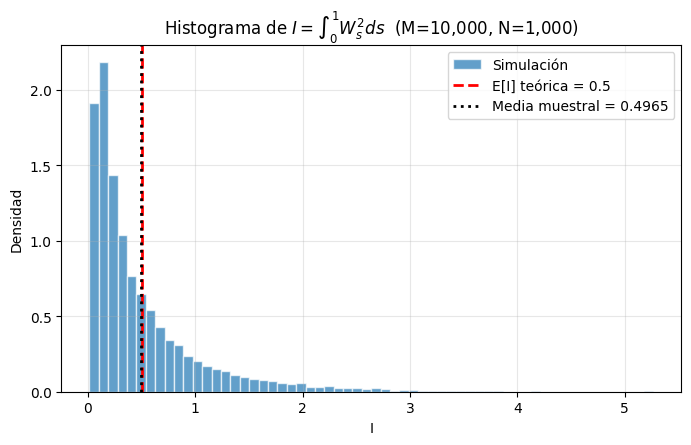

Asimetría: 2.565   Curtosis (exceso): 9.204


In [90]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(I, bins=60, density=True, alpha=.7, edgecolor="white", label="Simulación")
ax.axvline(media_teorica, color="red", ls="--", lw=2, label="E[I] teórica = 0.5")
ax.axvline(I_barra, color="black", ls=":", lw=2, label=f"Media muestral = {I_barra:.4f}")
ax.set_xlabel("I"); ax.set_ylabel("Densidad")
ax.set_title(f"Histograma de $I=\\int_0^1 W_s^2 ds$  (M={M:,}, N={N:,})")
ax.legend(); ax.grid(alpha=.3)
plt.show()

print(f"Asimetría: {stats.skew(I):.3f}   Curtosis (exceso): {stats.kurtosis(I):.3f}")

**Observación:** la distribución es **asimétrica a la derecha** y no gaussiana (como era de esperar, pues $I\ge 0$ es una forma cuadrática de gaussianas). Aun así, la media y la varianza coinciden con los valores teóricos.

### <span style="color:olive;">**Efecto de la discretización ($N$): sesgo de la suma de Riemann**</span>

Con la suma derecha, $t_i=i/N$ y $\mathbb{E}[W_{t_i}^2]=t_i$, así que el valor esperado **exacto del estimador discreto** es
$$\mathbb{E}[I_N]=\Delta t\sum_{i=1}^N t_i=\frac{N+1}{2N}=\frac12+\frac1{2N}.$$
Es decir, hay un pequeño **sesgo positivo** de orden $1/(2N)$ (para $N=1000$ vale $0.0005$, mucho menor que el error Monte Carlo $\approx 0.006$).
Se separan así los dos tipos de error: **sesgo por discretización** ($N$) y **error estadístico** ($M$).

In [91]:
from IPython.display import display, HTML

Ns = [5, 10, 50, 100, 500, 10000]
M_N = 20_000
filas = []
for n in Ns:
    In = simular_integral(M_N, n, T, batch=5000)
    filas.append({
        "N": n,
        "E[I_N] exacta discreta = (N+1)/(2N)": (n + 1) / (2 * n),
        "Media simulada": In.mean(),
        "Var simulada": In.var(ddof=1),
        "Error media vs 0.5": In.mean() - media_teorica,
    })
df_N = pd.DataFrame(filas).set_index("N")

# Forzar el renderizado en HTML
display(HTML(df_N.round(5).to_html()))

,E[I_N] exacta discreta = (N+1)/(2N),Media simulada,Var simulada,Error media vs 0.5
N,,,,
5,0.60000,0.60097,0.49579,0.10097
10,0.55000,0.54732,0.40010,0.04732
50,0.51000,0.50919,0.34963,0.00919
100,0.50500,0.50683,0.33794,0.00683
500,0.50100,0.49906,0.33625,-0.00094
10000,0.50005,0.49677,0.32392,-0.00323


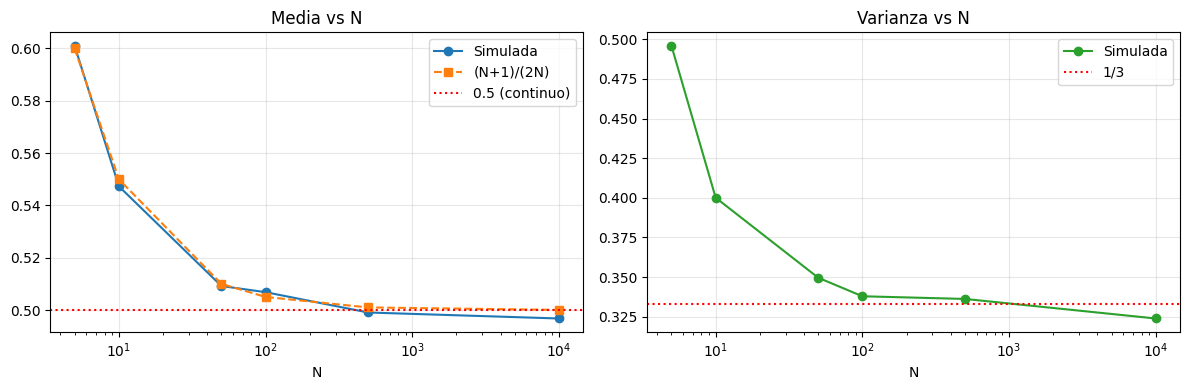

In [92]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df_N.index, df_N["Media simulada"], "o-", label="Simulada")
ax[0].plot(df_N.index, df_N.iloc[:, 0], "s--", label="(N+1)/(2N)")
ax[0].axhline(0.5, color="red", ls=":", label="0.5 (continuo)")
ax[0].set_xscale("log"); ax[0].set_xlabel("N"); ax[0].set_title("Media vs N"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(df_N.index, df_N["Var simulada"], "o-", color="tab:green", label="Simulada")
ax[1].axhline(1/3, color="red", ls=":", label="1/3")
ax[1].set_xscale("log"); ax[1].set_xlabel("N"); ax[1].set_title("Varianza vs N"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

Observemos que las simulaciones se acercan cada mas al valor exacto con $N=10,000$ simulaciones.

## <span style="color:teal;"> **Conclusiones**</span>
> * La media muestral $\bar I$ resulta cercana a $\mathbf{0.5}$ y la varianza muestral $S^2$ cercana a $\mathbf{0.3333}$, en concordancia con $\mathbb{E}[I]=t^2/2$ y $\mathrm{Var}[I]=t^4/3$ con $t=1$.
> * Los valores teóricos quedan dentro de los intervalos de confianza al 95 %, por lo que **la simulación confirma los resultados del Ejercicio 1**.
> *  Los estimadores convergen al aumentar $M$ (Ley de los Grandes Números); el error estadístico decrece.
> * La discretización introduce un sesgo determinista de orden $1/(2N)$ en la media, que desaparece cuando $N\to\infty$.
> * La distribución de $I$ es positiva y asimétrica, no normal; sin embargo, están completamente determinados por la teoría del movimiento browniano.
